# Algoritmo de Euclides

El MCD de dos enteros cumple $\text{mcd}(a, b) = \text{mcd}(b, a \bmod b)$ y $\text{mcd}(a, 0) = a$. Cada paso reduce mucho los números, así que el coste es $O(\log \min(a, b))$.

## 1. MCD iterativo

Implementar el algoritmo de Euclides con un bucle y comprobarlo contra `math.gcd`.

In [1]:
import math
import random

def mcd(a, b):
    while b:
        a, b = b, a % b
    return abs(a)

for _ in range(1000):
    a, b = random.randint(-10**6, 10**6), random.randint(0, 10**6)
    assert mcd(a, b) == math.gcd(a, b)
print(mcd(1470, 693), mcd(17, 5), mcd(0, 9))

21 1 9


## 2. MCD de una lista y mcm

Calcular el MCD y el mínimo común múltiplo de una lista de números usando que $\text{mcm}(a, b) = \frac{|a \cdot b|}{\text{mcd}(a, b)}$.

In [2]:
from functools import reduce

def mcd_lista(numeros):
    return reduce(mcd, numeros)

def mcm_lista(numeros):
    return reduce(lambda a, b: abs(a * b) // mcd(a, b), numeros)

print(mcd_lista([84, 36, 60]), mcm_lista([4, 6, 10]))

12 60


## 3. Euclides extendido

Encontrar $x$ e $y$ tales que $a x + b y = \text{mcd}(a, b)$ (identidad de Bézout) y usarlo para calcular el inverso modular de $a$ módulo $m$.

In [3]:
def euclides_extendido(a, b):
    if b == 0:
        return a, 1, 0
    g, x, y = euclides_extendido(b, a % b)
    return g, y, x - (a // b) * y

def inverso_modular(a, m):
    g, x, _ = euclides_extendido(a, m)
    if g != 1:
        return None
    return x % m

g, x, y = euclides_extendido(240, 46)
print(g, x, y, 240 * x + 46 * y)
print(inverso_modular(3, 11), inverso_modular(4, 8))
assert inverso_modular(17, 3120) == pow(17, -1, 3120)

2 -9 47 2
4 None


## 4. Ecuaciones diofánticas lineales

La ecuación $a x + b y = c$ tiene soluciones enteras si y solo si $g = \text{mcd}(a, b)$ divide a $c$. Multiplicando la identidad de Bézout por $c / g$ se obtiene una solución $(x_0, y_0)$, y todas las demás son $x = x_0 + \frac{b}{g} t$, $y = y_0 - \frac{a}{g} t$ con $t \in \mathbb{Z}$. Escribir una función que devuelva las soluciones con $x, y \ge 0$, comprobarla contra fuerza bruta y contar de cuántas formas se pagan 100 € con billetes de 5 € y monedas de 2 €.

In [4]:
def diofantica(a, b, c):
    g, x, y = euclides_extendido(a, b)
    if c % g:
        return None
    return x * (c // g), y * (c // g), b // g, a // g

def soluciones_no_negativas(a, b, c):
    # a, b > 0: x = x0 + db·t >= 0 y y = y0 - da·t >= 0 acotan t
    sol = diofantica(a, b, c)
    if sol is None:
        return []
    x0, y0, db, da = sol
    t_min, t_max = -(x0 // db), y0 // da
    return [(x0 + db * t, y0 - da * t) for t in range(t_min, t_max + 1)]

def diofantica_fuerza_bruta(a, b, c):
    return [(x, (c - a * x) // b) for x in range(c // a + 1) if (c - a * x) % b == 0]

random.seed(4)
for _ in range(1000):
    a, b, c = random.randint(1, 30), random.randint(1, 30), random.randint(0, 200)
    assert soluciones_no_negativas(a, b, c) == diofantica_fuerza_bruta(a, b, c)
    sol = diofantica(a, b, c)
    assert (sol is None) == (c % math.gcd(a, b) != 0)
    if sol:
        assert a * sol[0] + b * sol[1] == c

print(diofantica(6, 15, 7), diofantica(6, 15, 9))
pagos = soluciones_no_negativas(5, 2, 100)
print(len(pagos), "formas:", pagos[:4], "...")

None (-6, 3, 5, 2)
11 formas: [(0, 50), (2, 45), (4, 40), (6, 35)] ...


## 5. Teorema chino del resto

Si los módulos $m_1, \dots, m_k$ son primos entre sí dos a dos, el sistema $x \equiv r_i \pmod{m_i}$ tiene una única solución módulo $M = \prod m_i$: $x = \sum r_i M_i \, (M_i^{-1} \bmod m_i)$ con $M_i = M / m_i$. Implementarlo con el inverso modular y resolver el problema clásico de Sunzi: un número que entre 3 da resto 2, entre 5 da resto 3 y entre 7 da resto 2. Comprobarlo contra fuerza bruta.

In [5]:
def resto_chino(restos, modulos):
    M = math.prod(modulos)
    x = 0
    for r, m in zip(restos, modulos):
        Mi = M // m
        x += r * Mi * inverso_modular(Mi, m)
    return x % M

def resto_chino_fuerza_bruta(restos, modulos):
    return next(x for x in range(math.prod(modulos)) if all(x % m == r for r, m in zip(restos, modulos)))

print(resto_chino([2, 3, 2], [3, 5, 7]))

primos_entre_si = [3, 4, 5, 7, 11, 13]
random.seed(5)
for _ in range(300):
    modulos = random.sample(primos_entre_si, random.randint(1, 4))
    restos = [random.randrange(m) for m in modulos]
    assert resto_chino(restos, modulos) == resto_chino_fuerza_bruta(restos, modulos)

23


## 6. Peor caso: teorema de Lamé

Contar los pasos (divisiones) que hace Euclides y comprobar con fuerza bruta, para $b < a \le 1000$, que el menor $a$ que necesita $k$ pasos es el número de Fibonacci $F_{k+2}$ (con $b = F_{k+1}$): los Fibonacci consecutivos son el peor caso y por eso el coste es logarítmico. Dibujar el número de pasos de cada par como un mapa de calor.

{1: 2, 2: 3, 3: 5, 4: 8, 5: 13, 6: 21, 7: 34, 8: 55, 9: 89, 10: 144, 11: 233, 12: 377, 13: 610, 14: 987}


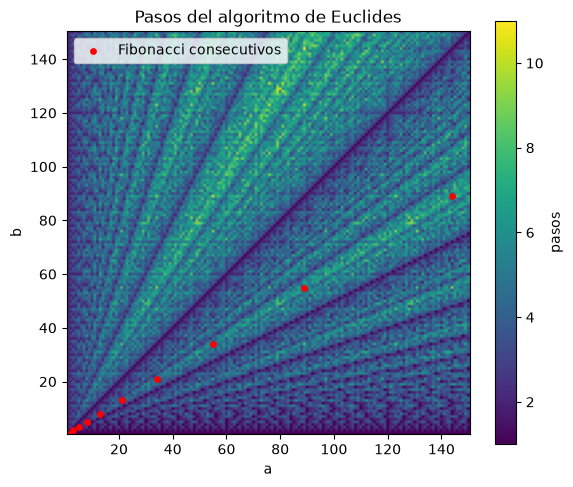

In [6]:
import matplotlib.pyplot as plt

def pasos(a, b):
    n = 0
    while b:
        a, b = b, a % b
        n += 1
    return n

N = 1000
menor_a = {}
for a in range(2, N + 1):
    for b in range(1, a):
        menor_a.setdefault(pasos(a, b), (a, b))

fib = [0, 1]
while len(fib) < 20:
    fib.append(fib[-1] + fib[-2])
for k, (a, b) in sorted(menor_a.items()):
    assert a == fib[k + 2] and pasos(fib[k + 2], fib[k + 1]) == k
print({k: a for k, (a, b) in sorted(menor_a.items())})

n = 150
matriz = [[pasos(a, b) for a in range(1, n + 1)] for b in range(1, n + 1)]
fig, eje = plt.subplots(figsize=(6.5, 5.5))
imagen = eje.imshow(matriz, origin="lower", extent=(0.5, n + 0.5, 0.5, n + 0.5), cmap="viridis")
eje.scatter(fib[3:13], fib[2:12], color="red", s=15, label="Fibonacci consecutivos")
eje.set(xlabel="a", ylabel="b", title="Pasos del algoritmo de Euclides")
fig.colorbar(imagen, label="pasos")
eje.legend(loc="upper left")
plt.show()